In [1]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack

from beeps import *

Welcome to JupyROOT 6.26/08


# Set config

In [2]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em18"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230301_18'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230301_18/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]

DUMP_PKL = True
DRAW_SR = True
RUN_SIDEBAND_MET = True
RUN_SIDEBAND_MASS = True
RUN_SIDEBAND_PT = True
DUMP_SIDEBAND_MET_PKL = True
DUMP_SIDEBAND_MASS_PKL = True
DUMP_SIDEBAND_PT_PKL = True
RUN_BTAG = False
EXPORT_VARIABLE = False

# # for dev
# ERA="ee17"
# DATE = '20230430wp80_17'
# INPUTDIR = "/eos/user/h/hkwon/Run2/"+DATE+"/ee/"


# Get input

In [3]:
lumi_all={
    "ee16pre":19520,
    "ee16post":16810,
    "ee17":41480,
    "ee18":59830,
    "mm16pre":19520,
    "mm16post":16810,
    "mm17":41480,
    "mm18":59830,    
#     "mm18":14000,    
    "em16pre":19520,
    "em16post":16810,
    "em17":41480,
    "em18":59830     
}

data_evts = {
    "ee16pre":652566543,
    "ee16post":287977113,
    "ee17":460041183,
    "ee18":1326465857,
    "mm16pre":458655573,
    "mm16post":327037312,
    "mm17":739073837,
#     "mm18":944842550,  #949352777 
    "mm18":949352777,  #949352777 
    "em16pre":1111222116,
    "em16post":615014425,
    "em17":1199115020,
#     "em18":2271308407   #2281001366  
    "em18":2281001366   #2281001366  
}

lumi=lumi_all[ERA]
print(ERA, lumi)

channel = ERA.replace("16pre", "")
channel = channel.replace("16post", "")
channel = channel.replace("17", "")
channel = channel.replace("18", "")

def get_df(root_file_name, unneccesary_columns):
    f = uproot.open(root_file_name)
    df = uproot.open(root_file_name)["Events_"+channel].arrays(library="pd")
    df_met_u = uproot.open(root_file_name)["Events_"+channel+"_met_u"].arrays(library="pd")
    df_met_d = uproot.open(root_file_name)["Events_"+channel+"_met_d"].arrays(library="pd")    
#     df_scale_u = uproot.open(root_file_name)["Events_"+channel+"_scale_u"].arrays(library="pd")
#     df_scale_d = uproot.open(root_file_name)["Events_"+channel+"_scale_d"].arrays(library="pd")
    info = uproot.open(root_file_name)["Info_"+channel].arrays(library="pd")
#     return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1), df_scale_u.drop(unneccesary_columns, axis=1), df_scale_d.drop(unneccesary_columns, axis=1)
    return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1)

unneccesary_columns = []
dic_input = {
    "ee16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/ee/",
    "mm16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/mm/",
    "em16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/em/",
    "ee16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/ee/",
    "mm16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/mm/",
    "em16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/em/",
    "ee17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/ee/",
    "mm17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/mm/",
    "em17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/em/",
    "ee18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/ee/",
    "mm18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/mm/",    
    "em18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/em/"        
#     "em18": "/eos/user/h/hkwon/Run2/20221120_18/em/"        
}
# input_dir = dic_input[ERA]
input_dir = INPUTDIR
f = []
for (dirpath, dirnames, filenames) in os.walk(input_dir):
    f.extend(filenames)
    break

dic_tup={}
for file in tqdm(f):
    # file naming: flatNtuple_Preselect_WZ1.root, flatNtuple_Preselect_Zp-3700_CH-1345.root
    if not "flatNtuple" in file:
        continue
#     if channel=="mm" and (fnmatch.fnmatch(file, '*E*Run*') or fnmatch.fnmatch(file, '*M*RunB*') or fnmatch.fnmatch(file, '*M*RunC*') or fnmatch.fnmatch(file, '*M*RunD*')): #temp
    if channel=="mm" and fnmatch.fnmatch(file, '*E*Run*'): #temp
        continue
    if channel=="ee" and fnmatch.fnmatch(file, '*M*Run*'):
        continue
#     if channel=="em" and fnmatch.fnmatch(file, '*E*Run*'):
#         continue  

    if "Zp" in file:
        sample=file.split('_')[2]+"_"+file.split('_')[3]
    else:
        sample=file.split('_')[2]
    sample=sample.rstrip('.root')
    try:
        print(sample)
        dic_tup[sample]=get_df(input_dir+file, unneccesary_columns)   
    except:
        print(sample)
        beep()        
        if "Run" in sample: # check file corrupt
            raise    
# dic_tup

ee17 41480


  0%|          | 0/217 [00:00<?, ?it/s]

DY0


  0%|          | 1/217 [00:00<01:59,  1.80it/s]

DY1


...

 99%|█████████▉| 215/217 [01:20<00:00,  2.40it/s]

Zp-4100_CH-595


100%|█████████▉| 216/217 [01:20<00:00,  2.40it/s]

Zp-4100_CH-845


100%|██████████| 217/217 [01:21<00:00,  2.67it/s]


In [4]:
beep_ok()

In [5]:
# for key in dic_tup:
#     print(key)

In [6]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTUp': 88.29, 'TTDown': 88.29, 'TThdampUp': 88.29, 'TThdampDown': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0

In [7]:
Data_concat, TT_concat, TTSemi_concat, TTZ_concat, DY_concat, top_concat, antitop_concat, WW_concat, WZ_concat, ZZ_concat = ([] for i in range(10))
Data_concat_met_u, TT_concat_met_u, TTSemi_concat_met_u, TTZ_concat_met_u, DY_concat_met_u, top_concat_met_u, antitop_concat_met_u, WW_concat_met_u, WZ_concat_met_u, ZZ_concat_met_u = ([] for i in range(10))
Data_concat_met_d, TT_concat_met_d, TTSemi_concat_met_d, TTZ_concat_met_d, DY_concat_met_d, top_concat_met_d, antitop_concat_met_d, WW_concat_met_d, WZ_concat_met_d, ZZ_concat_met_d = ([] for i in range(10))
Data_concat_scale_u, TT_concat_scale_u, TTSemi_concat_scale_u, TTZ_concat_scale_u, DY_concat_scale_u, top_concat_scale_u, antitop_concat_scale_u, WW_concat_scale_u, WZ_concat_scale_u, ZZ_concat_scale_u = ([] for i in range(10))
Data_concat_scale_d, TT_concat_scale_d, TTSemi_concat_scale_d, TTZ_concat_scale_d, DY_concat_scale_d, top_concat_scale_d, antitop_concat_scale_d, WW_concat_scale_d, WZ_concat_scale_d, ZZ_concat_scale_d = ([] for i in range(10))
TTUp_concat, TTDown_concat, TThdampUp_concat, TThdampDown_concat = ([] for i in range(4)) 
TTUp_concat_met_u, TTDown_concat_met_u, TThdampUp_concat_met_u, TThdampDown_concat_met_u = ([] for i in range(4)) 
TTUp_concat_met_d, TTDown_concat_met_d, TThdampUp_concat_met_d, TThdampDown_concat_met_d = ([] for i in range(4)) 

Data_nevts, TT_nevts, TTSemi_nevts, TTZ_nevts, DY_nevts, top_nevts, antitop_nevts, WW_nevts, WZ_nevts, ZZ_nevts = ([] for i in range(10))
TTUp_nevts, TTDown_nevts, TThdampUp_nevts, TThdampDown_nevts = ([] for i in range(4))

merged_dic_df={}
for key in dic_tup:
    if fnmatch.fnmatch(key, 'DY?') or fnmatch.fnmatch(key, 'DY??'):
        print(key)
        DY_concat.append(dic_tup[key][1])
        DY_concat_met_u.append(dic_tup[key][2])
        DY_concat_met_d.append(dic_tup[key][3])        
#         DY_concat_scale_u.append(dic_tup[key][4])
#         DY_concat_scale_d.append(dic_tup[key][5])
        DY_nevts.append(dic_tup[key][0])
        print(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TT?') or fnmatch.fnmatch(key, 'TT??'):
        TT_concat.append(dic_tup[key][1])
        TT_concat_met_u.append(dic_tup[key][2])
        TT_concat_met_d.append(dic_tup[key][3])
#         TT_concat_scale_u.append(dic_tup[key][4])
#         TT_concat_scale_d.append(dic_tup[key][5])
        TT_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TThdampUp?') or fnmatch.fnmatch(key, 'TThdampUp??'):
        TThdampUp_concat.append(dic_tup[key][1])
        TThdampUp_concat_met_u.append(dic_tup[key][2])
        TThdampUp_concat_met_d.append(dic_tup[key][3])
        TThdampUp_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TThdampDown?') or fnmatch.fnmatch(key, 'TThdampDown??'):
        TThdampDown_concat.append(dic_tup[key][1])
        TThdampDown_concat_met_u.append(dic_tup[key][2])
        TThdampDown_concat_met_d.append(dic_tup[key][3])
        TThdampDown_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTUp?') or fnmatch.fnmatch(key, 'TTUp??'):
        TTUp_concat.append(dic_tup[key][1])
        TTUp_concat_met_u.append(dic_tup[key][2])
        TTUp_concat_met_d.append(dic_tup[key][3])
        TTUp_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTDown?') or fnmatch.fnmatch(key, 'TTDown??'):
        TTDown_concat.append(dic_tup[key][1])
        TTDown_concat_met_u.append(dic_tup[key][2])
        TTDown_concat_met_d.append(dic_tup[key][3])
        TTDown_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTSemi*'):
        TTSemi_concat.append(dic_tup[key][1])
        TTSemi_concat_met_u.append(dic_tup[key][2])
        TTSemi_concat_met_d.append(dic_tup[key][3])
#         TTSemi_concat_scale_u.append(dic_tup[key][4])
#         TTSemi_concat_scale_d.append(dic_tup[key][5])
        TTSemi_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTZ*'):
        TTZ_concat.append(dic_tup[key][1])
        TTZ_concat_met_u.append(dic_tup[key][2])
        TTZ_concat_met_d.append(dic_tup[key][3])
#         TTZ_concat_scale_u.append(dic_tup[key][4])
#         TTZ_concat_scale_d.append(dic_tup[key][5])
        TTZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TW?'):
        top_concat.append(dic_tup[key][1])
        top_concat_met_u.append(dic_tup[key][2])
        top_concat_met_d.append(dic_tup[key][3])
#         top_concat_scale_u.append(dic_tup[key][4])
#         top_concat_scale_d.append(dic_tup[key][5])
        top_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TWa?'):
        antitop_concat.append(dic_tup[key][1])
        antitop_concat_met_u.append(dic_tup[key][2])
        antitop_concat_met_d.append(dic_tup[key][3])
#         antitop_concat_scale_u.append(dic_tup[key][4])
#         antitop_concat_scale_d.append(dic_tup[key][5])
        antitop_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'WW*'):
        WW_concat.append(dic_tup[key][1])
        WW_concat_met_u.append(dic_tup[key][2])
        WW_concat_met_d.append(dic_tup[key][3])
#         WW_concat_scale_u.append(dic_tup[key][4])
#         WW_concat_scale_d.append(dic_tup[key][5])
        WW_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'WZ*'):
        WZ_concat.append(dic_tup[key][1])
        WZ_concat_met_u.append(dic_tup[key][2])
        WZ_concat_met_d.append(dic_tup[key][3])
#         WZ_concat_scale_u.append(dic_tup[key][4])
#         WZ_concat_scale_d.append(dic_tup[key][5])
        WZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'ZZ*'):
        ZZ_concat.append(dic_tup[key][1])
        ZZ_concat_met_u.append(dic_tup[key][2])
        ZZ_concat_met_d.append(dic_tup[key][3])
#         ZZ_concat_scale_u.append(dic_tup[key][4])
#         ZZ_concat_scale_d.append(dic_tup[key][5])
        ZZ_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, '*Run*'):
        Data_concat.append(dic_tup[key][1])
        Data_concat_met_u.append(dic_tup[key][2])
        Data_concat_met_d.append(dic_tup[key][3])
#         Data_concat_scale_u.append(dic_tup[key][4])
#         Data_concat_scale_d.append(dic_tup[key][5])
        Data_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'Zp*'): 
        merged_dic_df[key]=dic_tup[key]
    if fnmatch.fnmatch(key, 'DY*To*'): 
        merged_dic_df[key]=dic_tup[key]
        print("high", key)

DY0
7798049
DY1
8244133
DY10
8510387
high DY1000To15000
DY11
8944052
DY12
9114037
DY13
9770787
DY14
8648737
DY15
1585487
high DY1500To20000
DY2
8666850
high DY2000To30000
DY3
6670651
DY4
9460659
DY5
9052002
high DY500To7000
DY6
7854873
DY7
8014614
high DY700To8000
DY8
10001888
high DY800To10000
DY9
9207802


In [8]:
# free memory 
dic_tup.clear()

In [9]:
totalinput = """
######################################################
####   Total input number of events (sumweight)   ####
######################################################
"""

print(totalinput)
if TT_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d)
    tmp = "TT: "+str(sum(TT_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TThdampUp_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TThdampUp']=sum(TThdampUp_nevts), pd.concat(TThdampUp_concat), pd.concat(TThdampUp_concat_met_u), pd.concat(TThdampUp_concat_met_d)
    tmp = "TThdampUp: "+str(sum(TThdampUp_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TThdampDown_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TThdampDown']=sum(TThdampDown_nevts), pd.concat(TThdampDown_concat), pd.concat(TThdampDown_concat_met_u), pd.concat(TThdampDown_concat_met_d)
    tmp = "TThdampDown: "+str(sum(TThdampDown_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTUp_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TTUp']=sum(TTUp_nevts), pd.concat(TTUp_concat), pd.concat(TTUp_concat_met_u), pd.concat(TTUp_concat_met_d)
    tmp = "TTUp: "+str(sum(TTUp_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TTDown_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TTDown']=sum(TTDown_nevts), pd.concat(TTDown_concat), pd.concat(TTDown_concat_met_u), pd.concat(TTDown_concat_met_d)
    tmp = "TTDown: "+str(sum(TTDown_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if TTSemi_concat:
#     merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d), pd.concat(TTSemi_concat_scale_u), pd.concat(TTSemi_concat_scale_d)
    merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d)
    tmp = "TTSemi: "+str(sum(TTSemi_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTZ_concat:
#     merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d), pd.concat(TTZ_concat_scale_u), pd.concat(TTZ_concat_scale_d)
    merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d)
    tmp = "TTZ: "+str(sum(TTZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if DY_concat:
#     merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d), pd.concat(DY_concat_scale_u), pd.concat(DY_concat_scale_d)
    merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d)
    tmp = "DY: "+str(sum(DY_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if top_concat:
    df=pd.concat(top_concat)
#     merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d), pd.concat(top_concat_scale_u), pd.concat(top_concat_scale_d)
    merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d)
    tmp = "top: "+str(sum(top_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if antitop_concat:
    df=pd.concat(antitop_concat)
#     merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d), pd.concat(antitop_concat_scale_u), pd.concat(antitop_concat_scale_d)
    merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d)
    tmp = "antitop: "+str(sum(antitop_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if ZZ_concat:
    df=pd.concat(ZZ_concat)
#     merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d), pd.concat(ZZ_concat_scale_u), pd.concat(ZZ_concat_scale_d)
    merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d)
    tmp = "ZZ: "+str(sum(ZZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WZ_concat:
    df=pd.concat(WZ_concat)
#     merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d), pd.concat(WZ_concat_scale_u), pd.concat(WZ_concat_scale_d)
    merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d)
    tmp = "WZ: "+str(sum(WZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WW_concat:
    df=pd.concat(WW_concat)
#     merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d), pd.concat(WW_concat_scale_u), pd.concat(WW_concat_scale_d)
    merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d)
    tmp = "WW: "+str(sum(WW_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if Data_concat:
#     merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d), pd.concat(Data_concat_scale_u), pd.concat(Data_concat_scale_d)
    merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d)
    tmp = "Data: "+str(sum(Data_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
# merged_dic_df["Zp-2500"]=dic_tup["Zp-2500"][0], dic_tup["Zp-2500"][1] 



######################################################
####   Total input number of events (sumweight)   ####
######################################################

TT: 112771456
TThdampUp: 39703672
TThdampDown: 38731490
TTUp: 42044778
TTDown: 38967610
TTSemi: 343257666
TTZ: 6911466
DY: 131545008
top: 5648712
antitop: 5673702
ZZ: 40753260
WZ: 24963396
WW: 7071358
Data: 460041183


In [10]:
os.system("mkdir -p "+DATE+"/Presel/"+ERA)
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'w') as f:
    f.write(totalinput)

In [11]:
print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts))

# try:
#    if data_evts[ERA]!=sum(Data_nevts):
#        raise ValueError('Data events missing!')
# except (ValueError, IndexError):
#    beep()
#    print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts)) 
#    raise

expected: 460041183 , while:  460041183


In [12]:
# # temp!!
for key in merged_dic_df:
    df = merged_dic_df[key][1]
    df_met_u = merged_dic_df[key][2]
    df_met_d = merged_dic_df[key][3]    
#     df_scale_u = merged_dic_df[key][4]
#     df_scale_d = merged_dic_df[key][5]
#     print(df[df.isin([np.inf, -np.inf]).any(1)])
    if df.isnull().values.any():
        print("Warning, nan in",key)
        i = df[df.isin([np.nan, np.inf, -np.inf]).any(1)].index
        print(i)
        df_new = df.drop(i)
        df_met_u_new = df_met_u.drop(i)
        df_met_d_new = df_met_d.drop(i)
#         print(df_new.isnull().values.any())
        #workaround for tuple assignment
#         merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new, df_scale_u, df_scale_d
        merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new
        


In [13]:
sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre', 'trigSF_pre']
# sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre']
eventweights = """
####################################################
####       event weights (normalization)        ####
####################################################
"""

def get_dic_with_weight(merged_dic_df):
    dic_df={}
    dic_df_met_u={}
    dic_df_met_d={}
    dic_df_scale_u={}
    dic_df_scale_d={}
    for key, vs in merged_dic_df.items():
        print(key)
        if "16pre" in ERA and key=="Zp-2500_CH-595": # signal sample missing
            continue    
        if "Data" in key:
            norm=1
        else:
            if fnmatch.fnmatch(key, '*DY*To*'):
                key = key[:len(key)-1]
            norm=lumi*dic_xsec[key]/vs[0]
        print(key, ":", norm)
        global eventweights
        eventweights+=key+":"+str(norm)+"\n"
#         print(eventweights)
        dic_df[key]=vs[1]
        dic_df_met_u[key] = vs[2]
        dic_df_met_d[key]=vs[3]
#         dic_df_scale_u[key] = vs[4]
#         dic_df_scale_d[key]=vs[5]
        dic_df[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_u[key]["weightmetUp"] = vs[1]["genweight_pre"]*norm
        dic_df_met_d[key]["weightmetDown"] = vs[1]["genweight_pre"]*norm
#         dic_df_scale_u[key]["weightscaleUp"] = vs[4]["totweight"].copy(deep=True)
#         dic_df_scale_d[key]["weightscaleDown"] =vs[5]["totweight"].copy(deep=True)
        dic_df[key]["wopu"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wol1"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["woeff"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wotop"] = vs[1]["genweight_pre"]*norm       
        dic_df[key]["wobsf"] = vs[1]["genweight_pre"]*norm       
      
        for s in sys:
            if s=="genweight_pre":
                continue
            dic_df[key]["weight"] *= vs[1][s]
            dic_df[key]["weighthdampUp"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weighthdampDown"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weightPSUp"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weightPSDown"] = dic_df[key]["weight"].copy(deep=True)
            dic_df_met_u[key]["weightmetUp"] *= vs[1][s]
            dic_df_met_d[key]["weightmetDown"] *= vs[1][s]
            # n-1 correction
            if s!="puweight_pre":
                dic_df[key]["wopu"] *= vs[1][s]
            if s!="l1prefiring_pre":
                dic_df[key]["wol1"] *= vs[1][s]
            if s!="effSF_pre":
                dic_df[key]["woeff"] *= vs[1][s]
#             if s!="topSF_pre":
            if not "top" in s:
                dic_df[key]["wotop"] *= vs[1][s]
            if s!="btagSF_pre":
                dic_df[key]["wobsf"] *= vs[1][s]
        #btag    
#         dic_df[key]["btag2"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF2_pre'] 
#         dic_df[key]["btagSF"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF_pre']
            
        # up, down    
        for s1 in sys:
            #if "top" in s1 or "eff" in s1:
            if "btag" in s1:
                continue
            s_u = s1.replace("_", "_u_")
            s_d = s1.replace("_", "_d_")
            if s1=="genweight_pre":
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_u])
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_d])
            else:
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_u]
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_d]             
#     return dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d
    return dic_df, dic_df_met_u, dic_df_met_d

# dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d = get_dic_with_weight(merged_dic_df)
dic_df, dic_df_met_u, dic_df_met_d = get_dic_with_weight(merged_dic_df)


DY1000To15000
DY1000To1500 : 0.006725273399735692
DY1500To20000
DY1500To2000 : 0.0008913829700309587
DY2000To30000
DY2000To3000 : 0.00019855513765608545
DY500To7000
DY500To700 : 0.0660359101064856
DY700To8000
DY700To800 : 0.014978640672124085
DY800To10000
DY800To1000 : 0.012300589428593817
Zp-1700_CH-345
Zp-1700_CH-345 : 0.009742269333333333
Zp-1700_CH-595
Zp-1700_CH-595 : 0.009742269333333333
Zp-1700_CH-845
Zp-1700_CH-845 : 0.009742269333333333
Zp-2100_CH-345
Zp-2100_CH-345 : 0.003312869333333333
Zp-2100_CH-595
Zp-2100_CH-595 : 0.003312869333333333
Zp-2100_CH-845
Zp-2100_CH-845 : 0.003312869333333333
Zp-2500_CH-345
Zp-2500_CH-345 : 0.0012156405333333333
Zp-2500_CH-595
Zp-2500_CH-595 : 0.0012156405333333333
Zp-2500_CH-845
Zp-2500_CH-845 : 0.0012156405333333333
Zp-2900_CH-1095
Zp-2900_CH-1095 : 0.0004889109333333333
Zp-2900_CH-1345
Zp-2900_CH-1345 : 0.0004889109333333333
Zp-2900_CH-345
Zp-2900_CH-345 : 0.0004889109333333333
Zp-2900_CH-595
Zp-2900_CH-595 : 0.0004889109333333333
Zp-2900_C

In [14]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(eventweights)

# Preselection

In [15]:
weihtedevents = """
#############################################################
####   unweighted (weighted) #events after preselection  ####
#############################################################
"""
dic_df_raw={}
dic_df_met_u_tmp = {}
dic_df_met_d_tmp = {}
# dic_df_scale_u_tmp = {}
# dic_df_scale_d_tmp = {}
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and roccoMET_pre>100"
query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>500 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and MET_pre>100"
# query_str="pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
# query_str="mass_pre>60"


for key in dic_df:  
    dic_df_raw[key]=dic_df[key].query(query_str)
    dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
    dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)    
#     dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#     dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str)
    unweighted_nevt = dic_df_raw[key].shape[0]
    print(key, ":", unweighted_nevt, "(", sum(dic_df_raw[key]["weight"]), ")")
    print(key, "(met_u) :", dic_df_met_u_tmp[key].shape[0])
    print(key, "(met_d) :", dic_df_met_d_tmp[key].shape[0])
#     print(key, "(scale_u) :", dic_df_scale_u_tmp[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d_tmp[key].shape[0])    
#     print(key, "(scale_u) :", dic_df_scale_u[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d[key].shape[0])
    weihtedevents+=key+":"+str(unweighted_nevt)+"("+str(sum(dic_df_raw[key]["weight"]))+")\n"
#     print(key, ":", unweighted_nevt, "(", unweighted_nevt*lumi*dic_xsec[key]/merged_dic_df[key][0], ")")

nested_dic_df={}
nested_dic_df["raw"]=dic_df_raw
nested_dic_df["met_u"]=dic_df_met_u_tmp
nested_dic_df["met_d"]=dic_df_met_d_tmp
# nested_dic_df["scale_u"]=dic_df_scale_u_tmp
# nested_dic_df["scale_d"]=dic_df_scale_d_tmp

DY1000To1500 : 758 ( 2.3819180460149934 )
DY1000To1500 (met_u) : 819
DY1000To1500 (met_d) : 702
DY1500To2000 : 1059 ( 0.4519599310249645 )
DY1500To2000 (met_u) : 1106
DY1500To2000 (met_d) : 1007
DY2000To3000 : 1439 ( 0.13488323371760022 )
DY2000To3000 (met_u) : 1493
DY2000To3000 (met_d) : 1382
DY500To700 : 355 ( 9.299591494460289 )
DY500To700 (met_u) : 413
DY500To700 (met_d) : 329
DY700To800 : 419 ( 3.2739657324376314 )
DY700To800 (met_u) : 456
DY700To800 (met_d) : 384
DY800To1000 : 580 ( 3.125633630988303 )
DY800To1000 (met_u) : 646
DY800To1000 (met_d) : 545
Zp-1700_CH-345 : 8892 ( 79.45851432368488 )
Zp-1700_CH-345 (met_u) : 8917
Zp-1700_CH-345 (met_d) : 8866
Zp-1700_CH-595 : 11055 ( 98.8746472466682 )
Zp-1700_CH-595 (met_u) : 11067
Zp-1700_CH-595 (met_d) : 11033
Zp-1700_CH-845 : 12194 ( 109.58128594402945 )
Zp-1700_CH-845 (met_u) : 12192
Zp-1700_CH-845 (met_d) : 12188
Zp-2100_CH-345 : 10610 ( 32.418529776677424 )
Zp-2100_CH-345 (met_u) : 10622
Zp-2100_CH-345 (met_d) : 10574
Zp-2100_

In [16]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(weihtedevents)

In [17]:
if DUMP_PKL:
    os.system("mkdir -p "+DATE+"/Presel/"+ERA)
    print("Dump pickle")
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

Dump pickle


# Draw

In [18]:
# draw
# get plot configuration
dic_variable={
    "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
#     "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
    "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#     "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
#     "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
#     "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
#     "U_pre": [14, 0, 660, "U [GeV]"],
#     "JZB_pre": [14, 80, 660, "JZB"],
#     "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#     "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#     "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#     "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
# # #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
# # #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
# # #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#     "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
#     "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# # #     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# # #     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#     "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
#     "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
#     "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF_pre": [100, 0, 10, "SV dxy"],     
}
if "em" in ERA:
    dic_variable["pt_el_pre"] = [15, 20,  660, "p_{T}(e) [GeV]"]
    dic_variable["pt_mu_pre"] = [15, 20,  660, "p_{T}(#mu) [GeV]"]
print(dic_variable)
list_variables = [(key, dic_variable[key]) for key in dic_variable]
print(list_variables)

{'PuppiMET_pre': [14, 100, 660, 'Puppi p_{T}^{miss} [GeV]'], 'mass_pre': [22, 100, 1000, 'M_{ll} [GeV]'], 'pt_lead_pre': [15, 80, 660, 'p_{T}(l_{lead}) [GeV]'], 'pt_trail_pre': [15, 40, 520, 'p_{T}(l_{trail}) [GeV]']}
[('PuppiMET_pre', [14, 100, 660, 'Puppi p_{T}^{miss} [GeV]']), ('mass_pre', [22, 100, 1000, 'M_{ll} [GeV]']), ('pt_lead_pre', [15, 80, 660, 'p_{T}(l_{lead}) [GeV]']), ('pt_trail_pre', [15, 40, 520, 'p_{T}(l_{trail}) [GeV]'])]


In [19]:
SYS_LIST = ["puweight", "l1prefiring", "effSF", "topSF", "met", "trigSF", "hdamp", "PS"]
# SYS_LIST = ["hdamp", "PS"]

In [20]:
import math
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met", "scale"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "met"]
sys_list = SYS_LIST
# sys_list = ["l1prefiring"]

def draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, r, region):
    """
        draw histograms with sys variations, return sys uncertainty dic
    """
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/norm_"+query_str)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        if "met" in s or "scale" in s: # fill later
            continue
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
    if "el_pre" not in variable and "mu_pre" not in variable and "PuppiMET_phi_pre" not in variable: #temp
        # shape sys
        hist=HistStack(dic_nested_shape_sys['met_u'], variable, 'weightmetUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_d'], variable, 'weightmetDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metDown'] = np.array(sysUp) - np.array(bkg_norm)

#     hist=HistStack(dic_nested_shape_sys['scale_u'], variable, 'weightscaleUp', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleUp'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_d'], variable, 'weightscaleDown', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleDown'] = np.array(sysUp) - np.array(bkg_norm) 
    else:
#         sys_list = ["puweight", "l1prefiring", "effSF", "topSF"]
        sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS"]
#         sys_list = ["hdamp", "PS"]
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
#     print(dic_sys)
#     print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr
        
# dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list, 'PuppiMET_pre', [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"])

In [21]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/sys")
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df_raw, nested_dic_df, sys_list, variable, dic_variable[variable], region)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr) 
    threshold = 1
    if region=='SR':
        if not 'phi' in variable and not 'eta' in variable:
#         if not 'eta' in variable:
            threshold = 0.3
        if "PuppiMET_pre" in variable:
            threshold = 0.5
        
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([2.58755560e+01, 0.00000000e+00, 0.00000000e+00, 1.38337598e+00,
       7.10501280e-01, 1.73222404e-01, 8.91053358e-03, 1.03503010e-01,
       7.41485655e-03, 3.69114348e-02, 3.10736718e-02, 3.06497629e-03,
       2.93972706e-02, 4.32493047e-03]), 'puweightDown': array([6.41183604e+00, 1.31544488e+00, 1.21028928e+00, 2.82898370e+00,
       4.62389498e-01, 1.13719640e-01, 4.05614059e-02, 3.60929892e-01,
       7.30911035e-03, 1.35392037e-02, 4.73246525e-02, 3.58530939e-03,
       2.78858139e-02, 1.03954532e-02]), 'l1prefiringUp': array([1.15172123e+03, 2.06557061e+02, 4.34995931e+01, 9.82450824e+00,
       1.98832964e+00, 4.81659665e-01, 1.43179414e-01, 3.75739600e-02,
       9.47946528e-03, 3.14745324e-03, 4.91411307e-04, 2.02568539e-04,
       5.68340777e-04, 1.93097148e-03]), 'l1prefiringDown': array([1.15494408e+03, 2.06749311e+02, 4.28395403e+01, 9.74754677e+00,
       1.98058894e+00, 4.81338622e-01, 1.39428782e-01, 3.79144500e-02,
       9.47354207e-03, 3.1658

         1.17875928,   0.93140447])}
{'puweightUp': array([4.48536415e+01, 1.98444252e+01, 2.23341157e+01, 9.45407894e-02,
       9.83548144e-01, 1.36786258e-01, 7.47127638e-03, 3.27711586e-01,
       1.28489530e-01, 0.00000000e+00, 9.57001557e-02, 1.76310593e-03,
       6.89065590e-02, 2.06644588e-03, 2.56548930e-03]), 'puweightDown': array([8.18624382e+01, 1.94880790e+01, 2.61329500e+00, 1.83434135e+00,
       1.78183300e+00, 4.53654793e-01, 0.00000000e+00, 2.53834855e-01,
       0.00000000e+00, 7.89478839e-02, 1.16558697e-01, 4.79123665e-03,
       3.67146230e-02, 0.00000000e+00, 7.95802123e-05]), 'l1prefiringUp': array([8.89718777e+02, 2.44743474e+02, 6.74779725e+01, 1.66636897e+01,
       2.04720506e+00, 9.43420206e-01, 1.37700739e-01, 6.25626515e-02,
       1.08215405e-03, 6.75208305e-03, 2.26042593e-03, 9.55851633e-04,
       2.03828418e-04, 1.33895993e-05, 1.19517638e-03]), 'l1prefiringDown': array([8.91031288e+02, 2.44024980e+02, 6.69819671e+01, 1.65746507e+01,
       2.134064

         1.91821505,   0.74399132,   0.96990777])}
{'puweightUp': array([5.96545044e+01, 2.01225903e+00, 2.06818048e+01, 1.91169307e+00,
       4.94847776e+00, 0.00000000e+00, 4.68000317e-01, 2.22294250e+00,
       2.60524487e-01, 2.63618592e-01, 1.21036905e-02, 0.00000000e+00,
       1.78257624e-02, 7.47031952e-03, 6.55753857e-03, 1.18361305e-02,
       1.80899898e-02, 1.75454149e-04, 3.74843090e-03, 8.22876353e-04,
       2.39038909e-04, 2.72601105e-03]), 'puweightDown': array([7.35859605e+01, 0.00000000e+00, 5.66575856e+01, 2.05343556e-01,
       1.47563565e+00, 7.83299750e-02, 7.33314426e-02, 2.83862972e+00,
       2.93382740e-01, 1.13106124e-02, 1.54985824e-01, 3.56961113e-03,
       7.80088193e-02, 0.00000000e+00, 3.83084058e-02, 1.21965317e-02,
       7.29883541e-03, 2.24519462e-03, 1.88348629e-03, 0.00000000e+00,
       9.98427592e-04, 8.15627971e-03]), 'l1prefiringUp': array([9.61160212e+01, 2.01623008e+02, 1.43442624e+02, 6.07804227e+01,
       3.02501363e+01, 1.48406418e+01,

        0.14517518,  0.63802078])}
{'puweightUp': array([4.12377481e+00, 4.73300682e+01, 2.69633446e+01, 6.77691581e-01,
       2.83467332e-01, 0.00000000e+00, 2.09457023e+00, 1.09771932e-03,
       2.03258548e-01, 0.00000000e+00, 2.70468446e-03, 5.62912683e-06,
       5.63121076e-05, 1.01212433e-03, 2.76833463e-04]), 'puweightDown': array([2.26117904e+01, 2.75500945e+01, 1.54225499e+01, 1.60507036e+00,
       3.76063541e-01, 4.85822620e-02, 2.81228009e+00, 4.31922509e-03,
       0.00000000e+00, 2.54080263e-03, 3.21154433e-02, 7.59169783e-04,
       1.34825208e-04, 5.81539343e-04, 1.42518370e-03]), 'l1prefiringUp': array([1.26307167e+03, 3.02733843e+02, 2.64410833e+01, 3.27315481e+00,
       2.53359438e-01, 6.21991128e-02, 6.11698196e-03, 2.35921586e-02,
       1.46750174e-03, 5.12792723e-04, 1.10791130e-04, 1.58306375e-04,
       4.90121084e-05, 1.58834619e-05, 9.44534692e-06]), 'l1prefiringDown': array([1.26193510e+03, 3.03233608e+02, 2.63661443e+01, 3.23689896e+00,
       2.56088801

       3.74131811e-02, 5.33903614e-02, 2.06436004e-01])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', '

Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/e

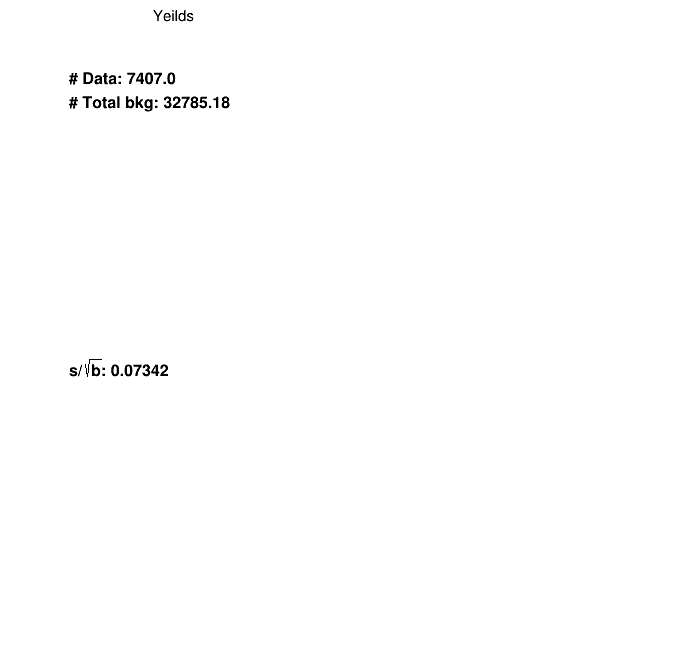

In [22]:
if DRAW_SR:
    region = "SR"

    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)

array('f', [10.651510238647461, 12.057334899902344, 17.994773864746094, 293.2737121582031, 665.6618041992188, 6483.357421875, 6752.201171875, 6607.94091796875, 6653.0595703125, 6665.35400390625, 201.58547973632812, 13.296531677246094])
test


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/SR/normblind_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/SR/normblind_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/SR/wotop/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/SR/wotop/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 202

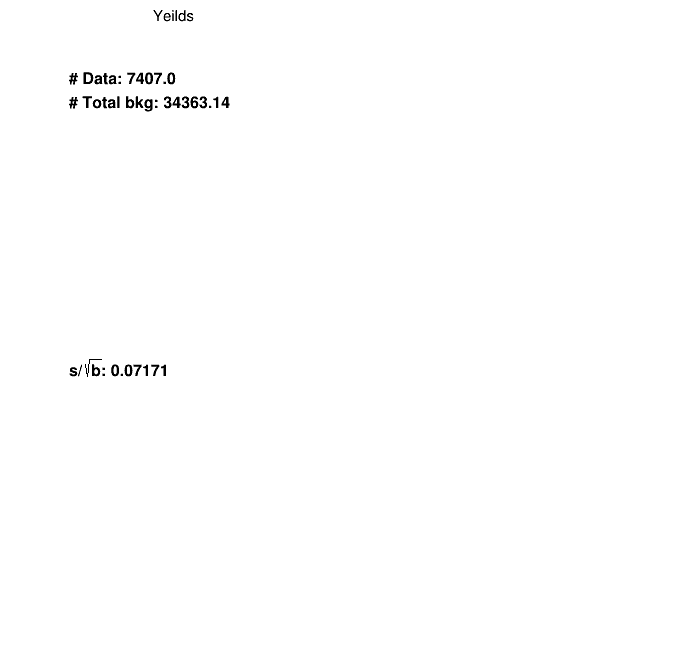

In [23]:
###### wotop ######
dic_variable={
    "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"], 
}
os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/wotop")

for variable, r in dic_variable.items():
    if not "Puppi" in variable:
        threshold = 0.3
    else:
        threshold = 0.5
    hist=HistStack(dic_df_raw, variable, "weight", r[0], r[1], r[2], r[3])  
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_"+query_str, blind_from=threshold)        
    hist=HistStack(dic_df_raw, variable, "wotop", r[0], r[1], r[2], r[3])  
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/norm_"+query_str, blind_from=threshold) 
hist.get_yeilds()
hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/pie_"+query_str)  

In [24]:
dic_df_raw["TT"]["trigSF_pre"]

0         0.987004
3         0.993395
26        0.996223
29        0.995788
32        0.996223
            ...   
124123    0.997417
124137    0.999469
124197    0.996223
124199    0.995576
124202    0.991751
Name: trigSF_pre, Length: 237406, dtype: float32

# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/SR/sig_eff.pdf has been created


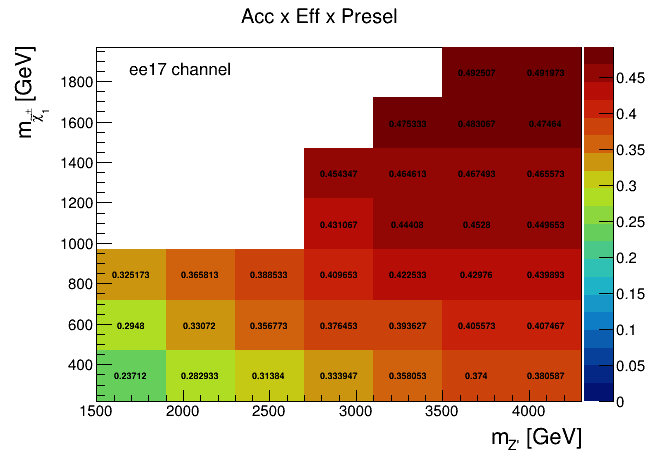

In [25]:
Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# # missing bin by hand
# h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
# h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz text")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+ERA+" channel}}")

c1.Draw()
c1.SaveAs(DATE+"/Presel/"+ERA+"/"+region+"/sig_eff.pdf")

# MET side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 478
DY1500To2000 : 444
DY2000To3000 : 470
DY500To700 : 434
DY700To800 : 379
DY800To1000 : 417
Zp-1700_CH-345 : 1284
Zp-1700_CH-595 : 971
Zp-1700_CH-845 : 742
Zp-2100_CH-345 : 1181
Zp-2100_CH-595 : 991
Zp-2100_CH-845 : 770
Zp-2500_CH-345 : 1089
Zp-2500_CH-595 : 897
Zp-2500_CH-845 : 734
Zp-2900_CH-1095 : 500
Zp-2900_CH-1345 : 504
Zp-2900_CH-345 : 1026
Zp-2900_CH-595 : 806
Zp-2900_CH-845 : 631
Zp-3300_CH-1095 : 541
Zp-3300_CH-1345 : 426
Zp-3300_CH-1595 : 353
Zp-3300_CH-345 : 996
Zp-3300_CH-595 : 777
Zp-3300_CH-845 : 590
Zp-3700_CH-1095 : 468
Zp-3700_CH-1345 : 388
Zp-3700_CH-1595 : 333
Zp-3700_CH-1845 : 301
Zp-3700_CH-345 : 872
Zp-3700_CH-595 : 717
Zp-3700_CH-845 : 569
Zp-4100_CH-1095 : 428
Zp-4100_CH-1345 : 348
Zp-4100_CH-1595 : 336
Zp-4100_CH-1845 : 302
Zp-4100_CH-345 : 808
Zp-4100_CH-595 : 652
Zp-4100_CH-845 : 595
T

       1.14513902e-02, 1.46452101e-01])}
here {'puweightUp': array([3.44997266e+01, 3.88194902e+01, 6.61475380e+02, 2.76297730e-02,
       2.56677097e+01, 4.95673623e+00, 2.30676201e-01, 3.70938475e-01,
       1.91248987e+00, 8.27680025e+00, 0.00000000e+00, 3.92413185e-02,
       0.00000000e+00, 2.12724622e-02, 8.89939435e-03, 1.84703803e-03,
       4.07766605e-04, 1.02159855e-04, 6.47091747e-03, 5.11070442e-04,
       1.05646268e-04, 5.26619302e-05, 2.23935069e-03, 1.10973301e-03,
       6.50364563e-04, 3.90955809e-07, 1.12904199e-03, 2.22375579e-05,
       7.50793385e-04, 2.76828544e-03]), 'puweightDown': array([1.00964646e+01, 4.43662727e+01, 2.12346431e+02, 1.06601551e+00,
       4.42948512e+00, 1.58439257e-01, 2.23964277e-01, 4.80491185e-02,
       1.61321455e+01, 3.04972728e+00, 6.20889845e-01, 5.89168880e-02,
       5.84112840e-02, 2.02633117e-03, 9.97790686e-05, 1.34667410e-03,
       5.21554090e-04, 1.95667664e-04, 5.26117314e-03, 4.12716851e-04,
       1.12120084e-03, 1.94487

       1.14513902e-02, 1.46452101e-01])}
{'puweightUp': array([2.97129835e+02, 2.67792187e+02, 1.34924730e+01, 1.12367315e+01,
       7.52129636e+00, 1.52700033e+00, 1.75320067e+00, 2.89089604e-01,
       1.08450845e+00, 8.82745223e-02, 8.80130695e-02, 4.91903541e-01,
       3.48686456e-02, 5.30054867e-01, 1.09340110e-02, 1.91169441e-02,
       0.00000000e+00, 1.88344491e-04, 0.00000000e+00, 4.23640053e-02,
       6.34661477e-03, 8.02694209e-04, 1.42555797e-03, 3.47116472e-04,
       1.40791242e-05, 1.35773072e-04, 3.47721964e-02, 3.74290762e-04,
       1.76184394e-04, 7.69487913e-05, 6.83216155e-04]), 'puweightDown': array([2.56047759e+01, 1.51745497e+02, 1.31059983e+01, 8.79715930e+00,
       7.14582766e+00, 4.45592748e-01, 6.12567747e+00, 2.15910906e-02,
       2.59838311e+00, 6.93905454e-01, 3.68481394e-03, 5.87481255e-01,
       9.91805696e-03, 7.85884199e-01, 4.91629713e-04, 4.06488072e-03,
       6.09761604e-02, 2.94731345e-05, 4.46114578e-02, 5.62653686e-02,
       8.81077088e-

       1.94316103e+00, 6.53425371e-02, 4.71314439e-02])}
here {'puweightUp': array([2.97129835e+02, 2.67792187e+02, 1.34924730e+01, 1.12367315e+01,
       7.52129636e+00, 1.52700033e+00, 1.75320067e+00, 2.89089604e-01,
       1.08450845e+00, 8.82745223e-02, 8.80130695e-02, 4.91903541e-01,
       3.48686456e-02, 5.30054867e-01, 1.09340110e-02, 1.91169441e-02,
       0.00000000e+00, 1.88344491e-04, 0.00000000e+00, 4.23640053e-02,
       6.34661477e-03, 8.02694209e-04, 1.42555797e-03, 3.47116472e-04,
       1.40791242e-05, 1.35773072e-04, 3.47721964e-02, 3.74290762e-04,
       1.76184394e-04, 7.69487913e-05, 6.83216155e-04]), 'puweightDown': array([2.56047759e+01, 1.51745497e+02, 1.31059983e+01, 8.79715930e+00,
       7.14582766e+00, 4.45592748e-01, 6.12567747e+00, 2.15910906e-02,
       2.59838311e+00, 6.93905454e-01, 3.68481394e-03, 5.87481255e-01,
       9.91805696e-03, 7.85884199e-01, 4.91629713e-04, 4.06488072e-03,
       6.09761604e-02, 2.94731345e-05, 4.46114578e-02, 5.62653686e-02

       1.94316103e+00, 6.53425371e-02, 4.71314439e-02])}
{'puweightUp': array([  0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
       980.1688073 ,  65.43479601,  19.18724592,   0.        ]), 'puweightDown': array([  0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
       344.34072504,  15.37830243,   5.36472767,  14.83897743]), 'l1prefiringUp': array([  0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
       11

        0.        , 73.52298402, 46.67630026, 61.15448551, 48.3574718 ])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
array('f', [3.28082537651062, 3.48506236076355, 10.045527458190918, 176.9761199951172, 358.5100402832031, 3352.017822265625, 3505.271484375, 3521.14794921875, 3519.99755859375, 3485.

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and Pup

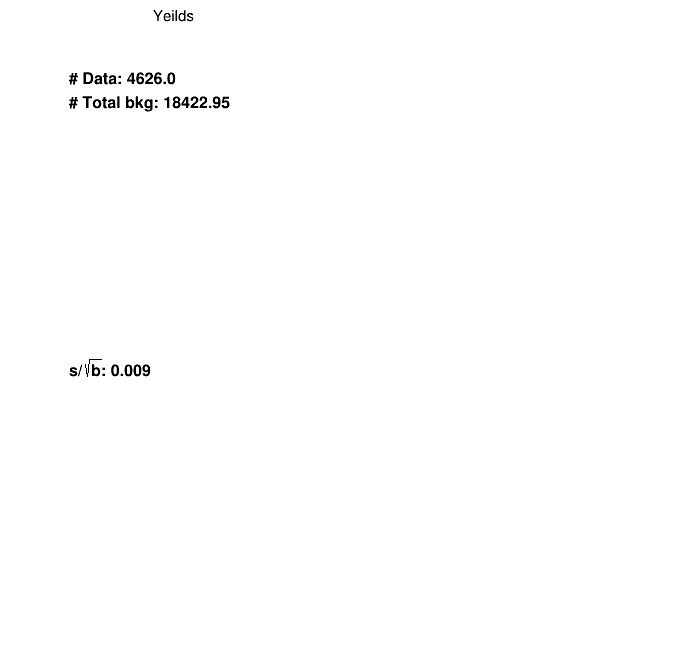

In [26]:
if RUN_SIDEBAND_MET:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "METSB"
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [27]:
if DUMP_SIDEBAND_MET_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_METSB.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# Mass side band

In [28]:
if RUN_SIDEBAND_MASS and not "em" in ERA:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    
    dic_variable={
        "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [1,80, 100, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    }

    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "MASSSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "mass_pre", "weight", 1, 80,  100, "M_{ll} [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.get_yeilds()
    hist.create_root_file(file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"] 
#     sys_list = ["puweight", "l1prefiring", "effSF", "topSF"] 
    for s in sys_list:
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Up', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Down', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist=HistStack(dic_df_met_u_tmp, "mass_pre", 'weightmetUp', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist=HistStack(dic_df_met_d_tmp, "mass_pre", 'weightmetDown', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")      

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 0
DY1500To2000 : 0
DY2000To3000 : 0
DY500To700 : 0
DY700To800 : 0
DY800To1000 : 0
Zp-1700_CH-345 : 16
Zp-1700_CH-595 : 395
Zp-1700_CH-845 : 1064
Zp-2100_CH-345 : 11
Zp-2100_CH-595 : 173
Zp-2100_CH-845 : 547
Zp-2500_CH-345 : 4
Zp-2500_CH-595 : 64
Zp-2500_CH-845 : 317
Zp-2900_CH-1095 : 314
Zp-2900_CH-1345 : 425
Zp-2900_CH-345 : 3
Zp-2900_CH-595 : 32
Zp-2900_CH-845 : 174
Zp-3300_CH-1095 : 225
Zp-3300_CH-1345 : 254
Zp-3300_CH-1595 : 377
Zp-3300_CH-345 : 3
Zp-3300_CH-595 : 18
Zp-3300_CH-845 : 110
Zp-3700_CH-1095 : 143
Zp-3700_CH-1345 : 206
Zp-3700_CH-1595 : 284
Zp-3700_CH-1845 : 290
Zp-3700_CH-345 : 6
Zp-3700_CH-595 : 10
Zp-3700_CH-845 : 73
Zp-4100_CH-1095 : 111
Zp-4100_CH-1345 : 187
Zp-4100_CH-1595 : 198
Zp-4100_CH-1845 : 209
Zp-4100_CH-345 : 1
Zp-4100_CH-595 : 8
Zp-4100_CH-845 : 64
TT : 53805
TThdampUp : 4211
TThdampD

       0.00000000e+00, 0.00000000e+00])}
here {'puweightUp': array([4.48868068e+01, 1.21148024e+02, 0.00000000e+00, 3.01869148e+00,
       1.76045015e+00, 1.19155587e+01, 3.45896841e+00, 2.15247448e+00,
       5.55546428e-01, 1.99185758e-01, 0.00000000e+00, 2.29386373e-01,
       5.12447756e-03, 1.42100505e-02, 1.77524750e-03, 4.71107690e-05,
       4.04463363e-04, 1.55057067e-05, 0.00000000e+00, 4.12175269e-05,
       3.59360103e-05, 0.00000000e+00, 0.00000000e+00, 2.79161988e-06,
       5.10133527e-06, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([8.91957420e+01, 1.64833470e+02, 1.83525471e+01, 1.62785790e+01,
       2.12239188e+00, 3.53039689e+01, 1.75615361e+01, 8.19798095e+00,
       3.49965520e-01, 3.09619578e-01, 3.33297898e-03, 1.72145892e-01,
       0.00000000e+00, 0.00000000e+00, 4.82194042e-03, 3.91512365e-05,
       1.40988168e-04, 2.84509985e-07, 0.00000000e+00, 3.28913650e-05,
       1.02294221e-05, 0.00000

       0.00000000e+00, 0.00000000e+00])}
{'puweightUp': array([1.77725957e+02, 8.01664023e-01, 6.08439939e-02, 5.92933188e+00,
       5.35265992e-03, 2.21849377e+00, 5.04663677e-01, 9.01265654e-02,
       4.12370832e-01, 8.22516520e-02, 6.78157631e-02, 6.34708302e-02,
       1.64371666e-02, 3.70948283e-03, 3.23801123e-04, 8.35338679e-03,
       0.00000000e+00, 1.06042188e-02, 1.97584342e-04, 9.21320844e-03,
       8.03073404e-03, 8.27686188e-04, 3.52200002e-04, 1.10492895e-04,
       4.29291824e-04, 6.46280635e-04, 2.77433849e-04, 9.79366684e-03]), 'puweightDown': array([5.99567526e+02, 2.59813228e-01, 1.85654528e+01, 1.33829733e+01,
       7.55428677e-01, 3.05937838e+00, 7.25980009e-01, 4.86890167e-01,
       7.08536652e-02, 5.25594298e-02, 7.54431281e-02, 1.47591348e-01,
       5.54129252e-02, 2.29956113e-02, 3.26371767e-04, 1.45692597e-02,
       1.07063261e-03, 2.20013975e-02, 1.50397479e-03, 1.05917182e-02,
       6.42808355e-03, 1.56730435e-04, 0.00000000e+00, 1.20393894e-04,
   

       2.20051164e-01, 2.12538700e-01, 3.27761566e-01, 6.00072887e-01])}
here {'puweightUp': array([1.77725957e+02, 8.01664023e-01, 6.08439939e-02, 5.92933188e+00,
       5.35265992e-03, 2.21849377e+00, 5.04663677e-01, 9.01265654e-02,
       4.12370832e-01, 8.22516520e-02, 6.78157631e-02, 6.34708302e-02,
       1.64371666e-02, 3.70948283e-03, 3.23801123e-04, 8.35338679e-03,
       0.00000000e+00, 1.06042188e-02, 1.97584342e-04, 9.21320844e-03,
       8.03073404e-03, 8.27686188e-04, 3.52200002e-04, 1.10492895e-04,
       4.29291824e-04, 6.46280635e-04, 2.77433849e-04, 9.79366684e-03]), 'puweightDown': array([5.99567526e+02, 2.59813228e-01, 1.85654528e+01, 1.33829733e+01,
       7.55428677e-01, 3.05937838e+00, 7.25980009e-01, 4.86890167e-01,
       7.08536652e-02, 5.25594298e-02, 7.54431281e-02, 1.47591348e-01,
       5.54129252e-02, 2.29956113e-02, 3.26371767e-04, 1.45692597e-02,
       1.07063261e-03, 2.20013975e-02, 1.50397479e-03, 1.05917182e-02,
       6.42808355e-03, 1.56730435e-04

       2.20051164e-01, 2.12538700e-01, 3.27761566e-01, 6.00072887e-01])}
{'puweightUp': array([5.74174146e+01, 9.66488106e+01, 5.28385265e-02, 3.21490591e+01,
       2.49051613e+00, 2.17866390e-01, 4.65903966e+01, 0.00000000e+00,
       8.53899625e-02, 0.00000000e+00, 2.49502165e-01, 2.54819655e-01,
       3.63599432e-02, 6.75521266e-02, 6.83646360e-01, 4.62858407e-03,
       3.52635817e+00, 9.61400199e-01, 4.24971408e-02, 1.88867799e-01,
       1.65574936e-01, 1.32419507e-02, 2.26300382e-01, 2.47834420e-01,
       5.13178742e-03, 1.29702867e-01, 2.25318842e-04, 6.88348718e-05,
       8.49153995e-02, 0.00000000e+00, 3.33402716e-04]), 'puweightDown': array([1.38285540e+02, 6.29719981e+01, 2.58865182e+01, 7.28285030e+01,
       1.30855583e+01, 1.05193116e+00, 2.12231509e+01, 4.83482526e+00,
       3.14976042e+00, 1.44071146e+00, 3.17686137e-02, 1.23144950e+00,
       0.00000000e+00, 7.39790478e-01, 6.78423509e-02, 2.30404360e-01,
       3.43035071e+00, 7.26077503e-01, 1.14352030e-01, 2.8

       9.19776373e-01, 1.65509178e-01, 3.27133730e+00])}
here {'puweightUp': array([5.74174146e+01, 9.66488106e+01, 5.28385265e-02, 3.21490591e+01,
       2.49051613e+00, 2.17866390e-01, 4.65903966e+01, 0.00000000e+00,
       8.53899625e-02, 0.00000000e+00, 2.49502165e-01, 2.54819655e-01,
       3.63599432e-02, 6.75521266e-02, 6.83646360e-01, 4.62858407e-03,
       3.52635817e+00, 9.61400199e-01, 4.24971408e-02, 1.88867799e-01,
       1.65574936e-01, 1.32419507e-02, 2.26300382e-01, 2.47834420e-01,
       5.13178742e-03, 1.29702867e-01, 2.25318842e-04, 6.88348718e-05,
       8.49153995e-02, 0.00000000e+00, 3.33402716e-04]), 'puweightDown': array([1.38285540e+02, 6.29719981e+01, 2.58865182e+01, 7.28285030e+01,
       1.30855583e+01, 1.05193116e+00, 2.12231509e+01, 4.83482526e+00,
       3.14976042e+00, 1.44071146e+00, 3.17686137e-02, 1.23144950e+00,
       0.00000000e+00, 7.39790478e-01, 6.78423509e-02, 2.30404360e-01,
       3.43035071e+00, 7.26077503e-01, 1.14352030e-01, 2.86693943e-02

       9.19776373e-01, 1.65509178e-01, 3.27133730e+00])}
{'puweightUp': array([102.56547635]), 'puweightDown': array([655.71687732]), 'l1prefiringUp': array([352.51646554]), 'l1prefiringDown': array([345.57655945]), 'effSFUp': array([4965.23502684]), 'effSFDown': array([4702.39052977]), 'topSFUp': array([29.24036734]), 'topSFDown': array([0.]), 'metUp': array([47404.06436288]), 'metDown': array([7915.01842669]), 'trigSFUp': array([52.82717687]), 'trigSFDown': array([63.13171216]), 'hdampUp': array([0]), 'hdampDown': array([595159.8466308]), 'PSUp': array([0]), 'PSDown': array([599729.88441765]), 'sum_up': array([230.01401887]), 'sum_down': array([1099.3505197])}
here {'puweightUp': array([102.56547635]), 'puweightDown': array([655.71687732]), 'l1prefiringUp': array([352.51646554]), 'l1prefiringDown': array([345.57655945]), 'effSFUp': array([4965.23502684]), 'effSFDown': array([4702.39052977]), 'topSFUp': array([29.24036734]), 'topSFDown': array([0.]), 'metUp': array([47404.06436288]), 

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_17/Presel/ee17/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pr

In [29]:
if DUMP_SIDEBAND_MASS_PKL and not "em" in ERA:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_MASS.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# PT side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 50
DY1500To2000 : 38
DY2000To3000 : 29
DY500To700 : 56
DY700To800 : 53
DY800To1000 : 41
Zp-1700_CH-345 : 1118
Zp-1700_CH-595 : 1012
Zp-1700_CH-845 : 834
Zp-2100_CH-345 : 1122
Zp-2100_CH-595 : 994
Zp-2100_CH-845 : 794
Zp-2500_CH-345 : 1030
Zp-2500_CH-595 : 955
Zp-2500_CH-845 : 836
Zp-2900_CH-1095 : 651
Zp-2900_CH-1345 : 553
Zp-2900_CH-345 : 988
Zp-2900_CH-595 : 922
Zp-2900_CH-845 : 788
Zp-3300_CH-1095 : 619
Zp-3300_CH-1345 : 483
Zp-3300_CH-1595 : 431
Zp-3300_CH-345 : 857
Zp-3300_CH-595 : 900
Zp-3300_CH-845 : 738
Zp-3700_CH-1095 : 608
Zp-3700_CH-1345 : 452
Zp-3700_CH-1595 : 402
Zp-3700_CH-1845 : 346
Zp-3700_CH-345 : 818
Zp-3700_CH-595 : 753
Zp-3700_CH-845 : 708
Zp-4100_CH-1095 : 555
Zp-4100_CH-1345 : 417
Zp-4100_CH-1595 : 386
Zp-4100_CH-1845 : 319
Zp-4100_CH-345 : 722
Zp-4100_CH-595 : 675
Zp-4100_CH-845 : 625
TT : 80

        6.0784214 ,  6.24471824,  5.33481565,  0.        ,  0.        ])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([2.52634145e+01, 7.37269125e-02, 1.05220739e-01, 1.63596258e-03,
       1.14616210e-01, 3.55894761e-02, 2.59722227e-02, 2.29523721e-02,
       7.70754737e-07, 2.80946728e-03, 5.64405576e-04, 3.59017798e-03,
       2.44006399e-06, 2.89530253e-03]), 'puweightDown': array([6.10570069e+00, 1.28655812e+00, 5.85539671e-02, 1.60660424e-02,
       6.17837753e-02, 9.72788748e-03, 1.96760383e-02, 3.07490146e-02,
       3.07749029e-05, 3.06154156e-03, 3.54539668e-04, 4.97842061e-04,
       3.61105128e-06, 1.37779887e-02]), 'l1prefiringUp': array([1.87065991e+01, 5.89323283e+00, 1.08776642e+00, 2.33103112e-01,
       4.81379981e-02, 3.42386104e-02, 4.20619006e-03, 6.88589843e-04,
 

        0.18963259,  0.2496707 ,  0.18989475,  0.15662433])}
{'puweightUp': array([2.87010611e-03, 8.87954164e-02, 5.56313513e-02, 4.25941090e-01,
       7.74715384e-02, 4.69462831e-03, 8.89324423e-02, 3.48839588e+00,
       0.00000000e+00, 1.48837459e-02, 2.82830317e+00, 8.28385267e+00,
       0.00000000e+00, 1.40257132e+00, 7.13164288e-01, 1.68674718e+00,
       0.00000000e+00]), 'puweightDown': array([0.05174419, 0.02606089, 0.0284713 , 0.32846087, 0.03239288,
       0.19102328, 0.0387681 , 0.18458053, 0.18021294, 0.06418415,
       5.42724672, 9.70961823, 0.05990986, 0.73947805, 1.14710255,
       0.5615683 , 0.        ]), 'l1prefiringUp': array([0.09707335, 0.13587315, 0.12221609, 0.2927304 , 0.21112834,
       0.57296237, 0.3936801 , 0.82758668, 1.77108472, 2.53169584,
       3.78691998, 4.56044732, 6.17131406, 5.5153805 , 6.32922094,
       2.90205166, 0.        ]), 'l1prefiringDown': array([0.09585281, 0.13437439, 0.12246882, 0.2865002 , 0.2084221 ,
       0.57294761, 0.3909590

        8.71232751,  0.        ])}
{'puweightUp': array([1.02622323e+00, 1.42622340e+00, 1.68501776e+01, 4.31115984e-01,
       1.44681635e-01, 2.11490256e-01, 1.43275802e-02, 6.79037314e-02,
       0.00000000e+00, 8.48560690e-01, 4.78473734e-01, 3.69231968e-02,
       6.39979394e-01, 2.75234672e+00, 3.41609454e+00, 1.59260192e+00,
       0.00000000e+00]), 'puweightDown': array([1.58194480e+00, 6.16878852e-02, 4.44923996e+00, 6.19401274e-01,
       7.82743051e-01, 4.06085102e-01, 1.95910300e-03, 4.97772034e-03,
       5.14930707e-02, 5.04855284e-01, 5.24741055e-01, 2.45910515e+00,
       0.00000000e+00, 4.62580810e+00, 6.40544893e+00, 2.39180825e+00,
       0.00000000e+00]), 'l1prefiringUp': array([1.84846175, 2.41042728, 2.17938799, 1.37302389, 1.005409  ,
       0.98016449, 0.8312793 , 0.62341324, 0.60952929, 0.67338353,
       1.10424934, 2.06441972, 1.904699  , 3.40813031, 3.43489011,
       3.83047952, 0.        ]), 'l1prefiringDown': array([1.82467798, 2.37917741, 2.1617643 , 1.3

       12.02225131,  0.        ])}
{'puweightUp': array([2.18436014e+00, 4.25875801e+00, 7.65941398e-01, 5.79922192e+00,
       4.59489971e-01, 2.06377096e-01, 5.43446044e-03, 0.00000000e+00,
       4.00494800e-02, 2.23524358e-01, 1.94731165e+00, 3.59682418e-02,
       4.70890327e-01, 1.52690597e+00, 2.37168719e+00, 2.81406747e+00,
       0.00000000e+00]), 'puweightDown': array([2.23880391e-01, 1.46689587e+00, 2.45090265e+00, 2.18883422e+00,
       9.42578191e-01, 1.02992048e-01, 3.59950545e-04, 5.33947533e-02,
       0.00000000e+00, 5.40068025e-01, 2.09395313e+00, 1.55623962e-03,
       1.69971148e+00, 1.73159059e+00, 5.14068724e+00, 3.65156342e+00,
       0.00000000e+00]), 'l1prefiringUp': array([2.1574377 , 2.3886135 , 1.77510604, 1.94832316, 1.09074847,
       0.72046456, 0.78213318, 0.63168212, 0.41342775, 0.60130359,
       1.19572076, 1.61430359, 2.05437892, 3.48706386, 5.0446027 ,
       3.01334212, 0.        ]), 'l1prefiringDown': array([2.13877653, 2.36059658, 1.75838915, 1.9

...

        0.19247717,  0.24756799,  0.19110558,  0.16841971,  0.2304535 ])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([3.26984460e+00, 5.49280905e+00, 3.98902773e+00, 1.68713430e-01,
       4.51108597e-02, 2.21181294e-01, 9.67572354e-03, 8.01501843e-03,
       3.95941869e-04, 6.81304652e-04, 1.78249892e-04, 1.11612616e-03,
       4.98544426e-05, 0.00000000e+00, 1.63171866e-05, 0.00000000e+00,
       6.02263041e-11, 1.94362203e-09, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([4.08970406e-01, 1.22552411e+01, 6.74979452e+00, 1.57761511e-02,
       0.00000000e+00, 1.43228959e-01, 1.36003474e-02, 7.15701520e-03,
       8.04060656e-04, 0.00000000e+00, 1.56287223e-04, 7.36380363e-04,
       1.15540597e-04, 1.36659130e-05, 1.07640928e-05, 0.00

       0.00000000e+00, 0.00000000e+00])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']puweightUp

puweightDown
l1prefiringUp
l1prefiringDo

        0.2462232 ,  0.18673811,  0.27036573,  0.49427183,  0.35388774])}
here {'puweightUp': array([0.00000000e+00, 0.00000000e+00, 1.71332599e-01, 1.37858869e+00,
       1.93359701e+00, 6.58912448e+00, 4.58816813e+00, 1.91450285e+00,
       2.12042273e+00, 1.24833247e+00, 5.00229585e-01, 3.88295923e-03,
       5.82948360e-02, 3.37204364e-01, 4.25003168e-02, 1.34360315e-02,
       1.54714902e-02, 1.62789842e-01, 9.05452871e-04, 4.95325845e-05,
       0.00000000e+00, 1.30440887e-04, 1.48561208e-06, 5.12680660e-04,
       2.46236767e-02]), 'puweightDown': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 3.90194360e+00,
       4.46184835e+00, 8.38584244e+00, 1.88128441e+00, 1.87427515e+00,
       1.61567594e+00, 3.40233306e-01, 4.56100766e-01, 2.54802454e-01,
       1.04467832e-01, 5.71892775e-02, 4.90075243e-02, 5.86752430e-02,
       1.69425811e-02, 2.88299820e-02, 3.07584745e-03, 7.63939971e-04,
       1.90206754e-03, 1.24145985e-03, 5.25728668e-05, 8.18978196e-04,
       5.7422

        0.59377263,  0.35051649,  0.18048916,  0.24286425])}l1prefiringUp
l1prefiringDown

effSFUphere
 effSFDown
topSFUp
topSFDown{'puweightUp': array([7.87694838e+00, 6.56156231e-01, 6.19605881e-02, 6.97721659e-02,
       2.54388172e-01, 0.00000000e+00, 9.16363290e-02, 6.55078300e-03,
       6.73089524e-04, 4.59111724e-04, 7.68605013e-04, 1.24248971e-02,
       3.14022665e-04, 1.19936077e-02]), 'puweightDown': array([3.98079760e+00, 2.47802316e+00, 0.00000000e+00, 2.55675177e-01,
       1.70725184e-01, 1.86810286e-03, 9.62981329e-02, 3.23042745e-02,
       3.34482008e-03, 4.89473915e-05, 2.10703652e-03, 3.92171241e-03,
       8.79372613e-05, 1.64873157e-02]), 'l1prefiringUp': array([1.37696975e+02, 2.50771969e+01, 3.69766967e+00, 7.24095373e-01,
       1.72247300e-01, 5.42185687e-02, 1.17856136e-02, 1.84052234e-03,
       2.93103203e-04, 3.11341728e-04, 1.31566076e-04, 1.99887604e-04,
       1.79780525e-06, 8.04171715e-06]), 'l1prefiringDown': array([1.38766548e+02, 2.50316504e+01, 3

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas:

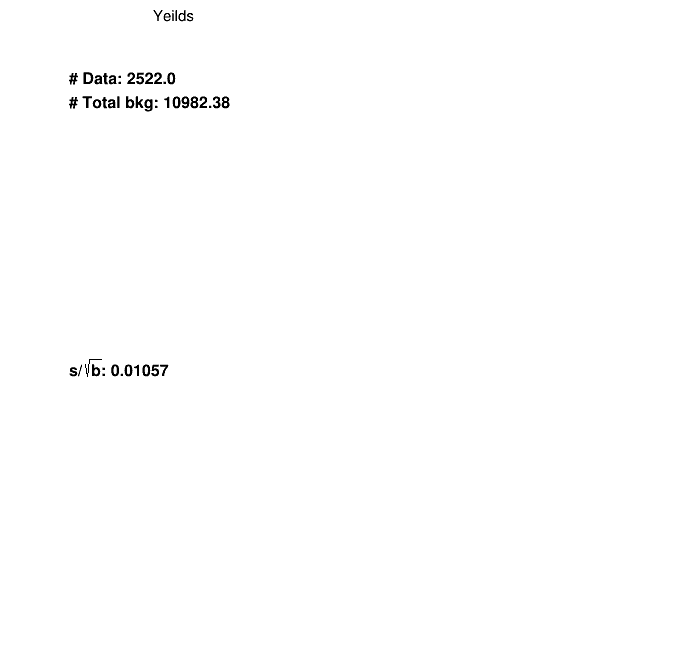

In [30]:
if RUN_SIDEBAND_PT:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
        "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
        "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [4, 0, 40, "p_{T}(l_{trail}) [GeV]"],
        "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
        "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
        "U_pre": [14, 0, 660, "U [GeV]"],
        "JZB_pre": [14, 80, 660, "JZB"],
        "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
        "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
        "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
        "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
        "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
        "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
        "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "PTSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS"]
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [31]:
if DUMP_SIDEBAND_PT_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_PT.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# b tag selection

In [32]:
if RUN_BTAG:
    dic_variable={
        "MET_pre": [25, 0, 500, "p_{T}^{miss} [GeV]"],    
#         "PuppiMET_pre": [50, 0, 500, "Puppi p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#         "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"], 
        "nbjetflav_pre": [10, 0, 10, "N bjetflav"], 
#         "nbjet_pre": [10, 0, 10, "N bjet"], 
        "njet_pre": [10, 0, 10, "N jet"], 
#         "njet_l_pre": [9, 1, 10, "N  l jet"],     
#         "njet_c_pre": [9, 1, 10, "N  c jet"],     
#         "njet_b_pre": [9, 1, 10, "N  b jet"],    
#         "btagSF0_pre": [40, 0.9, 1.3, "B SF"],    
    }
    
#     base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>80 and PuppiMET_pre>150 and MT_pre>130"
    base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    dic_df_raw={}
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and njet_pre==1" #temp!
#     query_str=base_line+" and nbjetflav_pre==0" #temp!
    query_str=base_line #temp!

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)  
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
        
    sys_list = ["weight", "wobsf", "wotop"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/Beq0/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/preselv1_"+query_str) 
    
#     hist=HistStack(dic_df_raw, "btagSF0_pre", "genweight_pre", 40, 0.9, 1.3, "B SF")            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/NONBTAG/"+sys_key+"/genweight_pre_preselv1_"+query_str, is_dnn=False) 

        #simply from last instance
        print(hist.get_yeilds())
        hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/pie_"+query_str)
        print(hist.nbin)    
    
#     with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_Beq0.pkl", "wb") as f:
#         pickle.dump(nested_dic_df, f)

# Export variables

In [33]:
if EXPORT_VARIABLE:
    # draw
    # get plot configuration
    dic_variable={
    #     "pt_trail_pre": [8, 40, 300, "p_{T}(l_{trail}) [GeV]"],
    #     "MT2_pre": [8, 0, 160, "M_{T2} [GeV]"],
        "H3PP_pre": [19, 95, 900, "H3PP [GeV]"],     
    }
    sys_src={
        "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre"]
    #     "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre", "topSF_pre"]
    }
    # sys_src=[]
    for key in dic_df_raw:
        if "Zp" in key:
            for variable, r in dic_variable.items():
                hist=HistStack(dic_df_raw, variable, sys_src, "presel", r[0], r[1], r[2], r[3])            
                c1=hist.draw_hist(key, ERA, ERA+"_exportdev"+query_str, True) 
                hist.create_root_file(key, variable, channel)
                hist.export_hist(key, variable, channel, "") 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie()
    print(hist.nbin)
